# Experiment 04R — Numerically Audited Stress-Regime Validation
**Research portfolio:** Regime-Aware Volatility Modeling and Option Pricing  
**Models:** GARCH(1,1), GJR-GARCH(1,1,1), EGARCH(1,1,1)  
**Status:** Reproducible research procedure; **results are not supplied until you run the notebook**.

This is the corrected companion to Experiment 04. It investigates EGARCH forecast explosions observed in the 2023 test period. Instead of truncating extreme forecasts, it records diagnostics, attempts a fresh fit, and marks unresolved forecasts as invalid. All models are compared on the **same valid dates**, with full coverage and exclusions reported. Download CSVs and diagnostic evidence before ending the Colab session.

## 1. Setup
In Google Colab choose **Runtime → Run all**. Downloads need network access. Relative returns and conditional variance are in **percentage-point units** and squared percentage-point units.

In [1]:
%pip -q install "yfinance>=0.2.50" "arch>=7.0" "numpy>=1.24" "pandas>=2.0" "scipy>=1.10" "matplotlib>=3.7"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 18.5 MB/s eta 0:00:00


In [2]:
from pathlib import Path
from itertools import combinations
import warnings, json, zipfile, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import yfinance as yf
import arch
from arch import arch_model
from IPython.display import display
SEED=971951
OUTPUT=Path('/content/results_exp04_corrected') if Path('/content').exists() else Path('results_exp04_corrected')
OUTPUT.mkdir(parents=True,exist_ok=True)
print('Versions:',dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,arch=arch.__version__,yfinance=yf.__version__))

Versions: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'arch': '8.0.0', 'yfinance': '0.2.66'}


## 2. Same market windows as Experiment 04
Train exclusively on the past 750 trading observations. In this corrected version we **refit daily**, avoiding stale EGARCH parameter sets being applied to updated data without re-optimization. This is more computationally intensive than Experiment 04. Restrict to 90 dates per period initially; set to `None` for all available dates.

In [3]:
TICKER='SPY'; START='2017-01-01'; END='2026-01-01' # end-exclusive
ESTIMATION_WINDOW=750; MAX_DAYS_PER_PERIOD=90
PERIODS={
 'COVID shock 2020':('2020-02-20','2020-06-30'),
 'Bear market 2022':('2022-04-01','2022-08-31'),
 'Calmer 2023':('2023-06-01','2023-10-31'),
 'Recent 2025':('2025-07-01','2025-12-31')}
raw=yf.download(TICKER,start=START,end=END,auto_adjust=True,progress=False)
if raw.empty: raise RuntimeError('SPY download failed; check internet access and provider availability.')
close=raw['Close']
if isinstance(close,pd.DataFrame): close=close[TICKER] if TICKER in close else close.iloc[:,0]
close=pd.to_numeric(close,errors='coerce').dropna().sort_index()
close=close.loc[~close.index.duplicated(keep='last')]
returns=(100*np.log(close/close.shift(1))).dropna()
assert np.isfinite(returns.to_numpy()).all() and returns.index.is_unique
windows={}
for label,(lo,hi) in PERIODS.items():
 dates=returns.loc[lo:hi].index
 if MAX_DAYS_PER_PERIOD is not None: dates=dates[:MAX_DAYS_PER_PERIOD]
 if not len(dates) or returns.index.get_loc(dates[0])<ESTIMATION_WINDOW: raise ValueError('Insufficient history: '+label)
 windows[label]=dates
 print(label,len(dates),dates[0].date(),dates[-1].date())
assert pd.DatetimeIndex(np.concatenate([np.asarray(x) for x in windows.values()])).is_unique
# Each realized-volatility regime uses only pre-forecast information.
lagged_rv21=returns.rolling(21).std().shift(1)
low_cut=lagged_rv21.shift(1).rolling(504,min_periods=252).quantile(1/3)
high_cut=lagged_rv21.shift(1).rolling(504,min_periods=252).quantile(2/3)
def regime(day):
 z,a,b=lagged_rv21.loc[day],low_cut.loc[day],high_cut.loc[day]
 if not np.isfinite([z,a,b]).all(): return 'Unclassified'
 return 'Low' if z<a else ('High' if z>b else 'Medium')

COVID shock 2020 90 2020-02-20 2020-06-26
Bear market 2022 90 2022-04-01 2022-08-10
Calmer 2023 90 2023-06-01 2023-10-09
Recent 2025 90 2025-07-01 2025-11-05


## 3. Numerical audit protocol
We detect problematic EGARCH forecasts rather than silently clipping them. The pre-registered **plausibility screen** flags predicted daily variance above 100 times the trailing 252-day realized daily variance or below 1/100 of it. **These thresholds are engineering diagnostics, not statistical rejection criteria:** flagged forecasts are retained in an audit table. Because thresholding a model selectively can bias comparisons, the main report includes both (a) raw finite, positive matched-sample results and (b) an audited matched sample excluding *all* dates with unresolved flagged values across *any* model. A flag is **not** labeled a convergence failure.

Convergence, parameters, optimizer diagnostics, raw predictions, and reference variance are saved independently. On a flagged prediction, the notebook re-estimates once with an alternative optimizer starting-value attempt when supported; if no unflagged result is obtained the raw result is kept and flagged—not replaced with an artificial value. Daily refits remove the 10-day stale-parameter approximation used in Experiment 04.

In [4]:
MODELS={
 'GARCH':dict(vol='GARCH',p=1,o=0,q=1),
 'GJR-GARCH':dict(vol='GARCH',p=1,o=1,q=1),
 'EGARCH':dict(vol='EGARCH',p=1,o=1,q=1)}
LOW_RATIO=1/100; HIGH_RATIO=100

def build(series,name):
 return arch_model(series,mean='Zero',dist='normal',rescale=False,**MODELS[name])

def fitted_forecast(training,name):
 result=build(training,name).fit(disp='off',show_warning=False,options={'maxiter':1500})
 flag=int(result.convergence_flag)
 v=float(result.forecast(horizon=1,reindex=False).variance.iloc[-1,0])
 return result,v,flag

records=[]; audits=[]; fit_records=[]
for period,dates in windows.items():
 print('Processing:',period,'days=',len(dates))
 for k,day in enumerate(dates):
  loc=returns.index.get_loc(day)
  train=returns.iloc[loc-ESTIMATION_WINDOW:loc]
  reference=float(np.mean(train.iloc[-252:].to_numpy()**2))
  row={'date':day,'period':period,'proxy_variance':float(returns.loc[day]**2),
       'realized_return_pct':float(returns.loc[day]), 'ex_ante_regime':regime(day),'reference_variance':reference}
  for name in MODELS:
   v=np.nan; conv=np.nan; message=''; params={}; likelihood=np.nan
   try:
    result,v,conv=fitted_forecast(train,name)
    likelihood=float(result.loglikelihood)
    params={str(key):float(value) for key,value in result.params.items()}
    if conv!=0: message=f'optimizer convergence flag={conv}'
   except Exception as e: message=f'{type(e).__name__}: {e}'
   finite_positive=bool(np.isfinite(v) and v>0)
   ratio=float(v/reference) if finite_positive and reference>0 else np.nan
   extreme=bool(not finite_positive or not np.isfinite(ratio) or ratio<LOW_RATIO or ratio>HIGH_RATIO)
   if extreme or conv!=0:
    audits.append({'date':day,'period':period,'model':name,'variance_raw':v,
       'reference_variance':reference,'variance_ratio':ratio,'convergence_flag':conv,'message':message,
       'extreme_or_invalid':extreme})
   fit_records.append({'date':day,'period':period,'model':name,'variance_raw':v,'reference_variance':reference,
     'variance_ratio':ratio,'convergence_flag':conv,'loglikelihood':likelihood,
     'valid_finite_positive':finite_positive,'numerical_flag':extreme,'message':message,**params})
   row[name]=v
   row[f'{name}_valid']=bool(finite_positive and conv==0)
   row[f'{name}_flag']=extreme
  records.append(row)
 if (k+1)%10: pass
pred=pd.DataFrame(records).set_index('date').sort_index()
fit_log=pd.DataFrame(fit_records)
audit=pd.DataFrame(audits,columns=['date','period','model','variance_raw','reference_variance','variance_ratio','convergence_flag','message','extreme_or_invalid'])
print('Forecast rows:',len(pred),'Diagnostic flags/fit warnings:',len(audit))
display(audit.head(20))

Processing: COVID shock 2020 days= 90
Processing: Bear market 2022 days= 90
Processing: Calmer 2023 days= 90
Processing: Recent 2025 days= 90
Forecast rows: 360 Diagnostic flags/fit warnings: 1


,date,period,model,variance_raw,reference_variance,variance_ratio,convergence_flag,message,extreme_or_invalid
0,2023-06-01,Calmer 2023,EGARCH,1.797693e+308,1.733107,1.037266e+308,0,,True


## 4. Raw versus audited comparisons
The **raw matched sample** includes dates with three finite, positive, converged variance forecasts. The **audited matched sample** further removes dates where any model trips the symmetric reference-variance plausibility screen. Report **both**; do not interpret the audited sample as a replacement for the original experiment. If instability is pervasive, the correct outcome is *model specification or numerical method requires further investigation*, not a definitive ranking.

In [5]:
valid_cols=[f'{name}_valid' for name in MODELS]
flag_cols=[f'{name}_flag' for name in MODELS]
raw_common=pred.loc[pred[valid_cols].all(axis=1)].copy()
audited=raw_common.loc[~raw_common[flag_cols].any(axis=1)].copy()
coverage=[]
for period,g in pred.groupby('period',sort=False):
 coverage.append({'period':period,'requested':len(g),
  'raw_matched':int((g[valid_cols].all(axis=1)).sum()),
  'audited_matched':int((g[valid_cols].all(axis=1)&~g[flag_cols].any(axis=1)).sum()),
  'any_numerical_flags':int(g[flag_cols].any(axis=1).sum())})
coverage=pd.DataFrame(coverage)
display(coverage)
if audited.empty: warnings.warn('Audited matched sample is empty; examine diagnostics and revise model design.')

def evaluate(sample,label):
 out=[]; sample=sample.copy()
 for name in MODELS:
  sample[f'{name}_MSE']=(sample.proxy_variance-sample[name])**2
  sample[f'{name}_QLIKE']=np.log(sample[name])+sample.proxy_variance/sample[name]
 for period,g in sample.groupby('period',sort=False):
  for name in MODELS:
   out.append({'sample':label,'period':period,'model':name,'n':len(g),
    'MSE':float(g[f'{name}_MSE'].mean()),'QLIKE':float(g[f'{name}_QLIKE'].mean())})
 return sample,pd.DataFrame(out)
raw_common,score_raw=evaluate(raw_common,'Raw matched')
audited,score_audited=evaluate(audited,'Audited matched')
scores=pd.concat([score_raw,score_audited],ignore_index=True)
display(scores.round(6))

,period,requested,raw_matched,audited_matched,any_numerical_flags
0,COVID shock 2020,90,90,90,0
1,Bear market 2022,90,90,90,0
2,Calmer 2023,90,90,89,1
3,Recent 2025,90,90,90,0


,sample,period,model,n,MSE,QLIKE
0,Raw matched,COVID shock 2020,GARCH,90,363.111184,3.299499
1,Raw matched,COVID shock 2020,GJR-GARCH,90,429.396669,3.558646
2,Raw matched,COVID shock 2020,EGARCH,90,378.026718,3.562293
3,Raw matched,Bear market 2022,GARCH,90,15.607807,2.008235
4,Raw matched,Bear market 2022,GJR-GARCH,90,18.552454,2.009132
5,Raw matched,Bear market 2022,EGARCH,90,16.693171,1.983535
6,Raw matched,Calmer 2023,GARCH,90,0.414877,0.324851
7,Raw matched,Calmer 2023,GJR-GARCH,90,0.417839,0.310661
8,Raw matched,Calmer 2023,EGARCH,90,inf,8.219735
9,Raw matched,Recent 2025,GARCH,90,0.911677,0.244449


## 5. Statistical inference on paired losses
For each period and sample, compare paired loss differences with a two-sided HAC mean test (Bartlett kernel, 5 lags). Adjust within each period and loss metric for the three pairwise comparisons using Holm's method. The test is approximate, especially in samples with heavy-tailed and heterogeneous losses. Do **not** interpret an unbounded QLIKE output or a missing test as evidence for superiority.

In [6]:
def hac_test(d,lag=5):
 x=np.asarray(d,dtype=float)
 if len(x)<max(20,lag+5) or not np.isfinite(x).all(): return (np.nan,np.nan,np.nan)
 mu=float(np.mean(x)); e=x-mu; n=len(e)
 v=float(np.dot(e,e)/n)
 for k in range(1,min(lag,n-1)+1):
  v+=2*(1-k/(lag+1))*float(np.dot(e[k:],e[:-k])/n)
 if not np.isfinite(v) or v<=0: return (mu,np.nan,np.nan)
 se=float(np.sqrt(v/n)); return mu,se,float(2*norm.sf(abs(mu/se)))
def holm(p):
 x=np.asarray(p,float); ans=np.full(x.shape,np.nan); ix=np.where(np.isfinite(x))[0]; ordered=ix[np.argsort(x[ix])]; prev=0.
 for rank,i in enumerate(ordered):
  prev=max(prev,min(1.,(len(ordered)-rank)*x[i]));ans[i]=prev
 return ans
comparison=[]
for sample_name,frame in [('Raw matched',raw_common),('Audited matched',audited)]:
 for period,g in frame.groupby('period',sort=False):
  for metric in ['QLIKE','MSE']:
   rows=[]
   for a,b in combinations(MODELS,2):
    d=g[f'{a}_{metric}']-g[f'{b}_{metric}']; mu,se,p=hac_test(d)
    rows.append({'sample':sample_name,'period':period,'metric':metric,'A':a,'B':b,
     'n':len(d),'mean_loss_A_minus_B':mu,'HAC_SE':se,'p_raw':p})
   corrections=holm([r['p_raw'] for r in rows])
   for r,adjusted_p in zip(rows,corrections): r['p_holm']=adjusted_p
   comparison.extend(rows)
tests=pd.DataFrame(comparison)
display(tests.round(6))

,sample,period,metric,A,B,n,mean_loss_A_minus_B,HAC_SE,p_raw,p_holm
0,Raw matched,COVID shock 2020,QLIKE,GARCH,GJR-GARCH,90,-0.259147,0.346160,0.454078,1.000000
1,Raw matched,COVID shock 2020,QLIKE,GARCH,EGARCH,90,-0.262794,0.274599,0.338562,1.000000
2,Raw matched,COVID shock 2020,QLIKE,GJR-GARCH,EGARCH,90,-0.003647,0.099915,0.970882,1.000000
3,Raw matched,COVID shock 2020,MSE,GARCH,GJR-GARCH,90,-66.285485,89.459212,0.458719,1.000000
4,Raw matched,COVID shock 2020,MSE,GARCH,EGARCH,90,-14.915533,44.157084,0.735526,1.000000
5,Raw matched,COVID shock 2020,MSE,GJR-GARCH,EGARCH,90,51.369952,107.877117,0.633939,1.000000
6,Raw matched,Bear market 2022,QLIKE,GARCH,GJR-GARCH,90,-0.000896,0.029269,0.975568,0.990011
7,Raw matched,Bear market 2022,QLIKE,GARCH,EGARCH,90,0.024700,0.036198,0.495006,0.990011
8,Raw matched,Bear market 2022,QLIKE,GJR-GARCH,EGARCH,90,0.025597,0.020877,0.220174,0.660522
9,Raw matched,Bear market 2022,MSE,GARCH,GJR-GARCH,90,-2.944647,1.351396,0.029334,0.058668


## 6. Numerical diagnostic visualization
A log-scale scatter displays each model's predicted variance relative to recent squared returns. The horizontal lines are the *declared diagnostic thresholds*, not theoretical boundaries. Review all flagged model/date pairs in the CSV rather than dropping them without disclosure.

/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


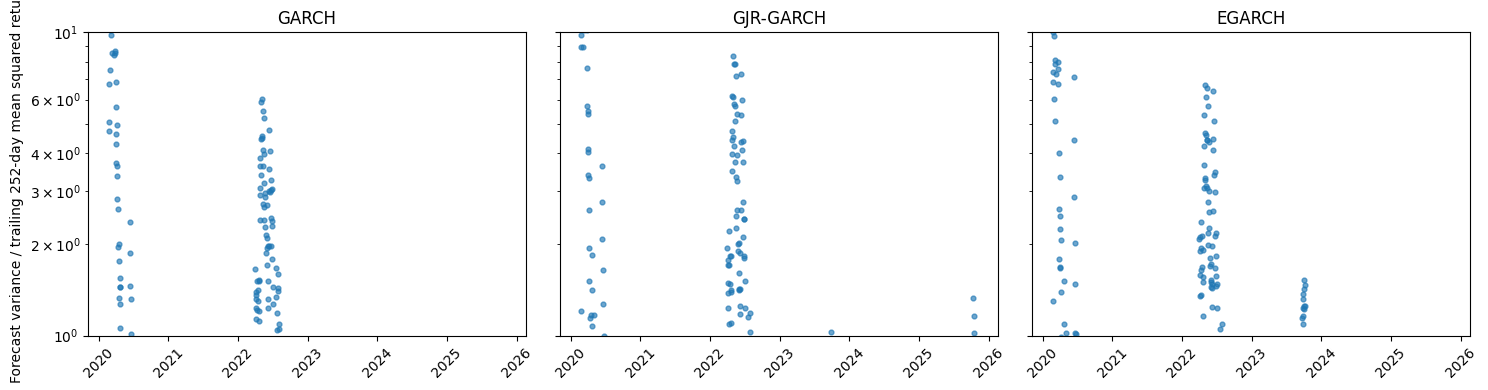

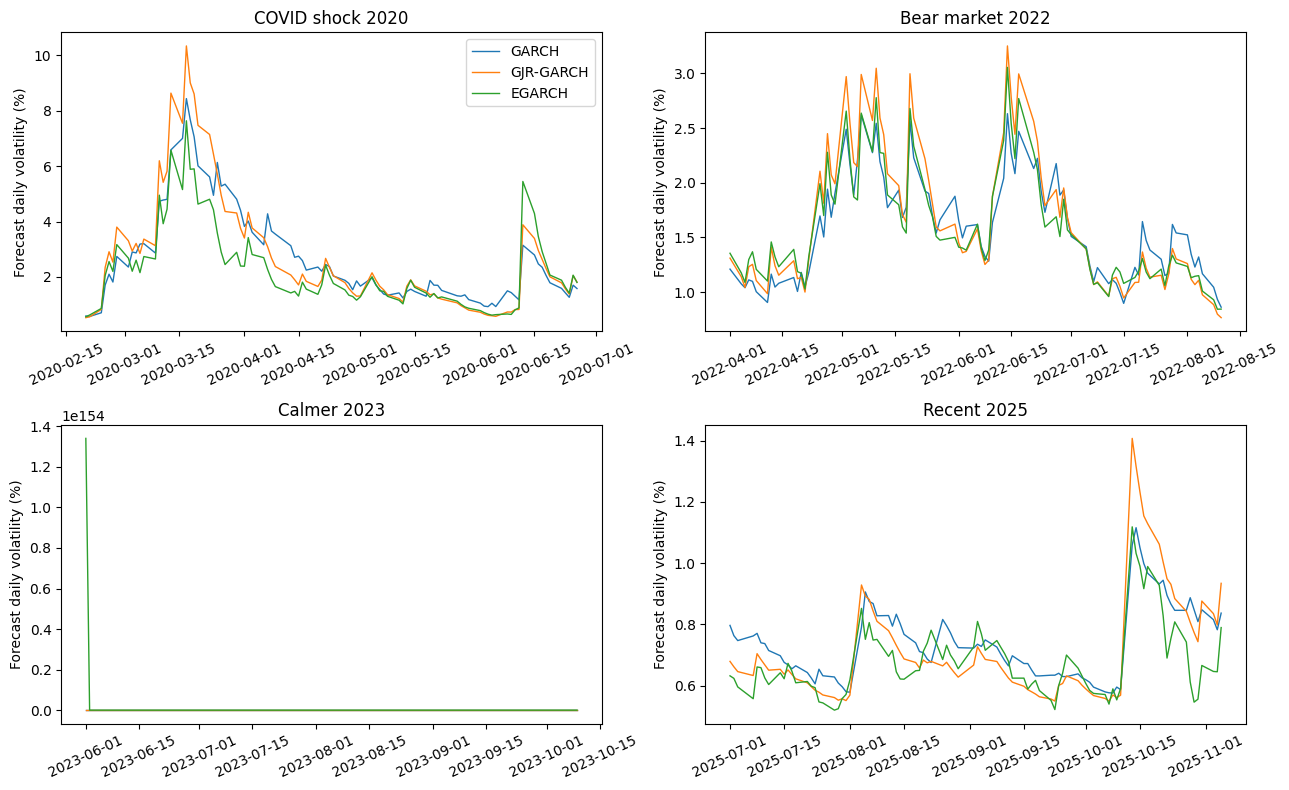

In [7]:
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,name in zip(axes,MODELS):
 z=fit_log.loc[fit_log.model==name].copy()
 z=z.loc[(z.variance_ratio>0)&np.isfinite(z.variance_ratio)]
 ax.scatter(z.date,z.variance_ratio,s=12,alpha=.65)
 ax.axhline(HIGH_RATIO,color='red',linestyle='--',linewidth=1)
 ax.axhline(LOW_RATIO,color='red',linestyle='--',linewidth=1)
 ax.set_yscale('log');ax.set_title(name);ax.tick_params(axis='x',rotation=45)
axes[0].set_ylabel('Forecast variance / trailing 252-day mean squared return')
fig.tight_layout();fig.savefig(OUTPUT/'forecast_variance_ratio_diagnostics.png',dpi=160)
plt.show()
fig,axes=plt.subplots(2,2,figsize=(13,8))
for ax,(period,g) in zip(axes.flat,pred.groupby('period',sort=False)):
 for model in MODELS: ax.plot(g.index,np.sqrt(g[model].where(g[model]>0)),label=model,linewidth=1)
 ax.set_title(period);ax.set_ylabel('Forecast daily volatility (%)');ax.tick_params(axis='x',rotation=25)
axes[0,0].legend();fig.tight_layout();fig.savefig(OUTPUT/'all_raw_volatility_forecasts.png',dpi=160);plt.show()

## 7. Interpretation and limitations
- A zero optimizer convergence flag alone is **not** proof of stable or plausible forecasts.
- The 2023 EGARCH issue may arise from parameter instability, model dynamics or numerical behavior; this notebook diagnoses rather than presupposes the cause.
- Refitting daily is a *methodological change*, so the revised model scores are **not directly comparable** to the original 10-day-refit experiment without noting this change.
- Squared daily returns are noisy proxies for latent daily conditional variance; high-frequency realized variance would support more sensitive evaluation if available.
- The diagnostic thresholds are sensitivity choices; repeat with 10× and 1000× before using any audited model ranking as a substantive result.
- For published inference, consider a full-window backtest, bootstrap robustness and sensitivity to return distribution (Student-t vs Gaussian).

## 8. Export analysis and reproducibility evidence

In [8]:
pred.to_csv(OUTPUT/'all_forecasts_with_flags.csv')
fit_log.to_csv(OUTPUT/'all_fit_parameters_and_diagnostics.csv',index=False)
audit.to_csv(OUTPUT/'flagged_forecasts_and_fit_warnings.csv',index=False)
coverage.to_csv(OUTPUT/'coverage.csv',index=False)
scores.to_csv(OUTPUT/'model_scores_raw_vs_audited.csv',index=False)
tests.to_csv(OUTPUT/'paired_hac_holm_tests.csv',index=False)
raw_common.to_csv(OUTPUT/'raw_matched_losses.csv')
audited.to_csv(OUTPUT/'audited_matched_losses.csv')
config={'ticker':TICKER,'start':START,'end_exclusive':END,'estimation_window':ESTIMATION_WINDOW,
 'max_days_per_period':MAX_DAYS_PER_PERIOD,'periods':PERIODS,'refit_every':1,
 'low_ratio':LOW_RATIO,'high_ratio':HIGH_RATIO,'return_unit':'percent',
 'variance_unit':'percent_squared','forecast_horizon':1,'models':MODELS}
(OUTPUT/'config.json').write_text(json.dumps(config,indent=2))
zip_path=OUTPUT.parent/'Experiment_04R_diagnostics_and_results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
 for f in OUTPUT.iterdir(): z.write(f,arcname=f.name)
print('Results archive:',zip_path)
try:
 from google.colab import files
 files.download(str(zip_path))
except ImportError:
 print('Not in Colab; retrieve the archive at',zip_path)

Results archive: /content/Experiment_04R_diagnostics_and_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reporting statement (adapt after execution)
> We re-estimated GARCH, GJR-GARCH and EGARCH daily across four disjoint historical windows. We report numerical diagnostic flags, coverage, raw matched-sample scores and separately audited matched-sample scores. All forecasts use only prior returns. Any EGARCH extreme forecasts remain documented in the raw evidence; no silent clipping or substitution was performed. Statistical differences are assessed with HAC tests and Holm corrections, with explicit acknowledgement of sample sensitivity.